# XFEL isomorphous density-difference maps

This notebook turns a pair of isomorphous crystal structures — typically a **DARK / reference** state and a **LIGHT / activated** state — into a signed $F_{\mathrm{LIGHT}}-F_{\mathrm{DARK}}$ difference electron-density map, extracts a fragment around a site of interest, and renders a publication-style figure in PyMOL.

The default example is photosystem II from the XFEL series of Ibrahim *et al.* (Science, 2020):

| Role | PDB | S-state | Notes |
| --- | --- | --- | --- |
| DARK | `6w1o` | 0F (dark-stable $S_1$) | reference amplitudes |
| LIGHT | `6w1v` | 2F, 200 ms | activated amplitudes; two OEC conformations |

The same cells work for any other isomorphous pair (1F vs 0F, 2F vs 1F, ligand-bound vs apo, …). Change the identifiers, file paths, site, and contour levels in the **configuration cell** and re-run.

## What the pipeline does

1. **Check** that the coordinate files, structure-factor mmCIF files, validation map-coefficient files, CCP4, Coot, and PyMOL are available.
2. **Convert** reflection mmCIF $\rightarrow$ MTZ (`cif2mtz`).
3. **Calculate model terms** with a zero-cycle REFMAC job (`NCYC 0`, no coordinate shift).
4. **Combine** LIGHT and DARK amplitudes with one phase set (`cad`).
5. **Scale** LIGHT amplitudes onto the DARK reference (`scaleit`).
6. **Fourier-transform** the signed difference $F_{\mathrm{LIGHT}}-F_{\mathrm{DARK}}$ (`fft`) and **extend** the map around the LIGHT model (`extends`).
7. **Export** a radius-limited map fragment around the chosen site with headless Coot.
8. **Contour** that fragment at user-defined $\pm n\sigma$ in PyMOL, **save a PNG**, and **display it in this notebook**.


## Background

A time-resolved or pump–probe XFEL experiment yields two (or more) isomorphous datasets. The chemically useful signal is the **difference electron density** (DED)

$$
\Delta\rho(\mathbf{r}) \;\propto\; \sum_{hkl} \big(|F_{\mathrm{LIGHT}}|-|F_{\mathrm{DARK}}|\big)\, e^{i\varphi_{\mathrm{ref}}}\, e^{-2\pi i \mathbf{h}\cdot\mathbf{r}}.
$$

This is the *difference-Fourier approximation*: the phases $\varphi_{\mathrm{ref}}$ come from a complete, well-refined model (or from a $2F_o-F_c$ map) rather than from the unknown true difference-vector phases. It is valid when the two crystals are **isomorphous** (same space group, very similar cell) and the structural change is local.

**How to read the map**

- **Positive** density (green $\rightarrow$ cyan $\rightarrow$ blue at increasing $\sigma$): more electrons in LIGHT than in DARK (an atom appeared or moved *to* this position).
- **Negative** density (red $\rightarrow$ salmon $\rightarrow$ magenta): more electrons in DARK than in LIGHT (an atom left this position).
- A chemically meaningful shift is a **negative peak on the old position** paired with a **positive peak on the new position**.

Difference maps from XFEL data are noisy and the activated-state occupancy is often only 10–30 %. Contouring at $3\sigma$ shows weaker (and noisier) features; $4$–$5\sigma$ keeps only the strongest peaks. There is no single “correct” level — report the level you used and inspect a range.

**Why SCALEIT comes before FFT.** Subtracting raw amplitudes from two data collections mixes true structural signal with scale, $B$-factor, and completeness differences. Isotropic (or anisotropic) scaling of LIGHT onto DARK puts both sets on a common scale. Monitor the SCALEIT $R$-factor: values $\lesssim 0.10$–$0.15$ are typical of isomorphous XFEL pairs that still yield a usable map; a much larger $R$ usually means non-isomorphism or a data-quality problem, not a larger chemical change.

**Phases used here.** A textbook DED map uses phases from the *reference* (DARK) model. This tutorial follows the published PSII comparison and, by default, takes `PHWT` from the **LIGHT** PDB validation $2F_o-F_c$ coefficients so that the map is on the same phase convention as that figure. You can switch `PHASE_SOURCE` to the DARK validation file or to a REFMAC `PHIC`/`PHWT` column if you want the classical construction.

**Files you need, per structure**

| File | Typical name | Where to get it |
| --- | --- | --- |
| Coordinates | `{pdbid}.pdb` | [RCSB](https://www.rcsb.org) “Download files” → PDB bundle (preferred for split PDB entries) |
| Structure factors | `{pdbid}-sf.cif` | RCSB → structure factors (mmCIF) |
| Validation $2F_o-F_c$ map coefficients | `{pdbid}_validation_2fo-fc_map_coef.cif` | RCSB validation report, or `https://files.rcsb.org/pub/pdb/validation_reports/xx/{pdbid}/{pdbid}_validation_2fo-fc_map_coef.cif.gz` |

The validation coefficient file supplies a `PHWT` column. It is **not** the difference map; it is only used as a phase source (and is converted to MTZ so `cad` can copy that column).


## How to choose parameters

Edit the **configuration cell** below. Everything downstream reads from that cell; you should not need to edit the CCP4/Coot/PyMOL code.

### Structures and files

- `DARK_ID` / `LIGHT_ID` are short labels used in output names (`6w1o`, `6w1v`, …). They do not have to be PDB codes.
- If you leave a path as `None`, it is built from the naming convention above inside `INPUT_DIR`.
- Override any path when your files are named differently (`6w1v.pdb` instead of `6w1v-pdb-bundle1.pdb`, mmCIF coordinates, …). Both `.pdb` and `.cif` coordinates are accepted by REFMAC.

### Resolution (`RESOLUTION_SOURCE`, `LOWRES`, `DMIN`)

- `RESOLUTION_SOURCE = "sf"` reads both structure-factor MTZs after `cif2mtz` and uses their **common** shell: the poorer low-resolution limit and the poorer high-resolution limit.
- `RESOLUTION_SOURCE = "explicit"` ignores that range and uses the `LOWRES` and `DMIN` numbers in the configuration cell. `DMIN` should be no finer than the worse of the two datasets.
- Very low-resolution terms are sensitive to bulk solvent and scaling. Set them with explicit `LOWRES` when you want a tighter cutoff than the MTZ range.

### Site of interest

- `SITE_CHAIN` and `SITE_RESI` centre the Coot export and the PyMOL view.
- For **6w1v**, chain `A` residue **416** is ligand `OEY`, the major (75 %) 2F OEC conformation that includes O6. Residue **415** is `OEX`, the minor conformation without O6. The DARK structure `6w1o` stores the unique OEC as `OEX` at residue **414** — residue numbers are **not** interchangeable across PDB entries. Always confirm with the residue-scan cell.
- `SITE_COPIES` may list several `(chain, resi)` pairs if you want one map fragment per monomer.
- `EXTRA_RESIDUES` are neighbouring amino acids drawn as sticks (D1-Glu189 in the default example).
- `SITE_LABEL` is only used in file names (`OEC`, `heme`, `chromophore`, …).

### $\pm\sigma$ contour

- `SIGMA_LEVELS = [3, 4, 5]` draws three nested meshes, matching the usual PSII figure.
- Use a single value, e.g. `[4.0]`, for a cleaner image.
- `SIGMA_POSITIVE` / `SIGMA_NEGATIVE` can be set independently if you want, for example, $+5\sigma$ / $-3\sigma$.
- `surface_representation = "mesh"` (default) draws a wireframe (`isomesh`). `"solid"` draws a transparent surface (`isosurface`).
- `CONTOUR_MODE = "sigma"` (default) lets PyMOL normalise the CCP4 map to RMS = 1, so a level of `3` **is** $3\sigma$. `"absolute"` turns that normalisation off and treats the numbers as raw map units.

### Map fragment

- `EXPORT_RADIUS_A` (default 10 Å) is the Coot clip radius around the site centroid.
- `CARVE_A` (default 3 Å) hides mesh that is farther than this from any displayed atom, so the cage does not swallow the model.
- `MAP_BORDER_A` (default 5 Å) is the `extends` padding around the LIGHT coordinates.

### Re-runs

- `RECOMPUTE_MAP = False` reuses an existing extended CCP4 map (the slow REFMAC/FFT steps).
- `RECOMPUTE_FRAGMENT = False` reuses an existing Coot `.map` clip.
- PyMOL is always re-run so that contour, colour, and camera changes are cheap to iterate.
- `INSPECT_IN_PYMOL = True` opens that scene in the PyMOL GUI after the PNG is shown. Quit PyMOL after moving the camera; the notebook stores the view and redraws the figure.


In [1]:
from __future__ import annotations

import os
import re
import shutil
import subprocess
import sys
from pathlib import Path

try:
    from IPython.display import Image, Markdown, display
except ImportError:  # running as a plain script rather than a notebook
    def display(obj=None, **kwargs):
        print(getattr(obj, "data", obj))

    class Image:  # noqa: N801
        def __init__(self, filename=None, width=None):
            self.filename = filename

        def __repr__(self):
            return f"[image {self.filename}]"

    class Markdown:  # noqa: N801
        def __init__(self, data=""):
            self.data = data

        def __repr__(self):
            return str(self.data)

# ---------------------------------------------------------------------------
# Configuration — edit this cell for a new isomorphous pair
# ---------------------------------------------------------------------------

NOTEBOOK_DIR = Path.cwd().resolve()

DARK_ID = "6w1o"          # reference / dark / 0F
LIGHT_ID = "6w1v"         # activated / light / 2F

INPUT_DIR = NOTEBOOK_DIR / "data"     # where the downloaded PDB / sf / validation files live
OUTPUT_DIR = NOTEBOOK_DIR / "work-1a"
print(f"OUTPUT DIRECTORY: {OUTPUT_DIR}")

# Leave a path at None to use the standard RCSB-style name inside INPUT_DIR.
DARK_PDB = None           # e.g. INPUT_DIR / "6w1o-pdb-bundle1.pdb"
LIGHT_PDB = None
DARK_SF = None            # e.g. INPUT_DIR / "6w1o-sf.cif"
LIGHT_SF = None
DARK_VALIDATION = None    # e.g. INPUT_DIR / "6w1o_validation_2fo-fc_map_coef.cif"
LIGHT_VALIDATION = None

CCP4_ROOT = Path("/Applications/ccp4-9")

# Resolution cutoffs for scaleit and fft, in Å.
# "sf" reads both structure-factor MTZs after cif2mtz and uses their common shell:
# the poorer low-resolution limit and the poorer high-resolution limit.
# "explicit" uses the LOWRES and DMIN numbers below and ignores the MTZ range.
RESOLUTION_SOURCE = "sf"  # "sf" or "explicit"
LOWRES = 20.0              # explicit low-resolution cutoff (Å); ignored when SOURCE is "sf"
DMIN = 2.10                # explicit high-resolution cutoff (Å); ignored when SOURCE is "sf"

if RESOLUTION_SOURCE == "explicit":
    LOWRES = float(LOWRES)
    DMIN = float(DMIN)
    if not (LOWRES > DMIN > 0):
        raise ValueError(f"Expected LOWRES > DMIN > 0, got {LOWRES} and {DMIN}")
    print(f"Explicit resolution: low {LOWRES:.3f} Å, high {DMIN:.3f} Å")
elif RESOLUTION_SOURCE == "sf":
    print("Resolution cutoffs will be read from the structure-factor MTZs in the map cell.")
else:
    raise ValueError(
        "RESOLUTION_SOURCE must be 'sf' or 'explicit', "
        f"got {RESOLUTION_SOURCE!r}"
    )

MAP_BORDER_A = 5.0        # EXTENDS border around the LIGHT model (Å)
print(f"Map border: {MAP_BORDER_A}")

# "light_validation" matches the published PSII tutorial figure.
# Alternatives: "dark_validation", "light_refmac", "dark_refmac".
PHASE_SOURCE = "light_validation"
print(f"Phase source: {PHASE_SOURCE}")

SITE_CHAIN = "A"
SITE_RESI = 416           # 6w1v OEY (major 2F OEC, includes O6)
SITE_LABEL = "OEC"
SITE_COPIES = [           # Coot exports one fragment per entry
    (SITE_CHAIN, SITE_RESI),
]
EXTRA_RESIDUES = [        # drawn as sticks in PyMOL; empty list is fine
    {"chain": "A", "resi": 189, "label": "GLU189"},
]

EXPORT_RADIUS_A = 10.0
CARVE_A = 3.0

SIGMA_LEVELS = [3.0, 4.0, 5.0]
SIGMA_POSITIVE = None     # None → SIGMA_LEVELS
SIGMA_NEGATIVE = None     # None → SIGMA_LEVELS
CONTOUR_MODE = "sigma"    # "sigma" or "absolute"
surface_representation = "mesh"  # "mesh" or "solid"
if surface_representation not in {"mesh", "solid"}:
    raise ValueError(
        "surface_representation must be 'mesh' or 'solid', "
        f"got {surface_representation!r}"
    )
print("Sigma levels: [" + ", ".join(f"±{level}" for level in SIGMA_LEVELS) + "]")
print(f"Surface representation: {surface_representation}")

SHOW_OEC_BONDS = True     # Mn/Ca–O bonds if those atom names exist
DRAW_DEFAULT_OEC_DISTANCES = True

# Published 6w1v chain-A OEC camera. Set to None to auto-orient on the site.

PYMOL_VIEW = None

#PYMOL_VIEW = '''\
#-0.222551167, -0.711501896, -0.666503847,\
# 0.638767481,  0.410044461, -0.651020229,\
# 0.736502111, -0.570636272,  0.363232195,\
# 0.000000000,  0.000000000, -42.280372620,\
#-34.986000061, 39.219001770, 364.061004639,\
# 37.280372620, 47.280372620, -20.000000000'''

# Set True to open the rendered scene in the PyMOL GUI after the PNG is shown.
# Quit PyMOL when the camera looks right; the figure is redrawn and a PYMOL_VIEW
# matrix is printed so you can paste it above.
INSPECT_IN_PYMOL = True

PNG_WIDTH = 1600
PNG_HEIGHT = 800
RAY_TRACE = True

RECOMPUTE_MAP = False
RECOMPUTE_FRAGMENT = False

POS_COLORS = ["forest", "cyan", "blue", "density"]
NEG_COLORS = ["red", "salmon", "magenta", "hotpink"]


OUTPUT DIRECTORY: /Users/souda/Documents/Projects/Batista/XFEL-tutorial/XFEL-notebook/work-1a
Low resolution cutoff: 20.0
High resolution cutoff: 2.1
Map border: 5.0
Phase source: light_validation
Sigma levels: [±3.0, ±4.0, ±5.0]


In [2]:
# ---------------------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------------------

def _standard_name(pdb_id: str, kind: str) -> Path:
    names = {
        "pdb": f"{pdb_id}.pdb",
        "sf": f"{pdb_id}-sf.cif",
        "validation": f"{pdb_id}_validation_2fo-fc_map_coef.cif",
    }
    return INPUT_DIR / names[kind]


def resolve_inputs() -> dict[str, Path]:
    files = {
        "dark_pdb": Path(DARK_PDB) if DARK_PDB else _standard_name(DARK_ID, "pdb"),
        "light_pdb": Path(LIGHT_PDB) if LIGHT_PDB else _standard_name(LIGHT_ID, "pdb"),
        "dark_sf": Path(DARK_SF) if DARK_SF else _standard_name(DARK_ID, "sf"),
        "light_sf": Path(LIGHT_SF) if LIGHT_SF else _standard_name(LIGHT_ID, "sf"),
        "dark_validation": Path(DARK_VALIDATION) if DARK_VALIDATION else _standard_name(DARK_ID, "validation"),
        "light_validation": Path(LIGHT_VALIDATION) if LIGHT_VALIDATION else _standard_name(LIGHT_ID, "validation"),
    }
    return {k: v.expanduser().resolve() for k, v in files.items()}


def require_files(files: dict[str, Path]) -> None:
    missing = [f"{k}: {p}" for k, p in files.items() if not p.is_file() or p.stat().st_size == 0]
    if missing:
        raise FileNotFoundError(
            "Missing or empty input files:\n  " + "\n  ".join(missing)
        )


def find_ccp4(root: Path) -> Path:
    root = Path(root).expanduser()
    setup = root / "bin" / "ccp4.setup-sh"
    if not setup.is_file():
        raise FileNotFoundError(
            f"CCP4 setup script not found at {setup}. "
            "Install CCP4 or set CCP4_ROOT to the suite prefix (e.g. /Applications/ccp4-9)."
        )
    return root


def find_coot(ccp4_root: Path) -> Path:
    for candidate in (ccp4_root / "bin" / "coot", Path(shutil.which("coot") or "")):
        if candidate.is_file():
            return candidate
    raise FileNotFoundError("Coot not found. CCP4 installs it at $CCP4/bin/coot.")


def find_pymol() -> Path:
    exe = shutil.which("pymol")
    if not exe:
        raise FileNotFoundError("PyMOL not found on PATH. Install pymol (conda-forge) or add it to PATH.")
    return Path(exe)


def run_bash(script: str, log_path: Path | None = None) -> str:
    wrapped = (
        "set -eo pipefail\n"
        'export SSL_CERT_FILE="${SSL_CERT_FILE:-}"\n'
        f'source "{CCP4_ROOT}/bin/ccp4.setup-sh"\n'
        "set -eo pipefail\n"
        f'cd "{OUTPUT_DIR}"\n'
        f"{script}\n"
    )
    proc = subprocess.run(
        ["/bin/bash", "-c", wrapped],
        text=True,
        capture_output=True,
    )
    out = (proc.stdout or "") + (proc.stderr or "")
    if log_path is not None:
        log_path.write_text(out)
    if proc.returncode != 0:
        tail = out[-5000:] if out else "(no output)"
        raise RuntimeError(f"Command failed (exit {proc.returncode}):\n{script}\n\n{tail}")
    return out


def run_ccp4(program: str, kv: list[tuple[str, Path | str]], keywords: str, log_path: Path) -> str:
    parts = [program]
    for key, value in kv:
        parts.append(str(key))
        parts.append(f'"{value}"')
    body = " ".join(parts) + " << 'EOF'\n" + keywords.strip() + "\nEOF"
    print(f"→ {program}  ({log_path.name})")
    return run_bash(body, log_path)


def mtz_labels(mtz_path: Path) -> list[str]:
    text = run_ccp4("mtzdump", [("hklin", mtz_path)], "END", OUTPUT_DIR / f"{mtz_path.stem}_mtzdump.log")
    labels: list[str] = []
    capture = False
    for line in text.splitlines():
        if "Column Labels" in line:
            capture = True
            continue
        if capture:
            stripped = line.strip()
            if stripped.startswith("*") and labels:
                break
            if stripped.startswith("*"):
                continue
            labels.extend(stripped.split())
    return labels


def mtz_resolution_angstrom(mtz_path: Path) -> tuple[float, float]:
    """Return (low-resolution Å, high-resolution Å) from the mtzdump log."""
    log_path = OUTPUT_DIR / f"{mtz_path.stem}_mtzdump.log"
    text = log_path.read_text(errors="replace")
    match = re.search(
        r"Resolution Range\s*:.*?([0-9.]+)\s*-\s*([0-9.]+)\s*A",
        text,
        flags=re.S,
    )
    if not match:
        raise RuntimeError(f"Could not read resolution limits from {log_path}")
    a, b = float(match.group(1)), float(match.group(2))
    return max(a, b), min(a, b)


def pick_label(labels: list[str], candidates: list[str], what: str) -> str:
    upper = {lab.upper(): lab for lab in labels}
    for name in candidates:
        if name.upper() in upper:
            return upper[name.upper()]
    raise KeyError(
        f"No {what} column among {candidates}. MTZ labels were: {labels}"
    )


def scan_hetatm(pdb_path: Path, skip_resnames: set[str] | None = None) -> list[dict]:
    skip_resnames = skip_resnames or {"HOH", "WAT", "DOD", "H2O"}
    residues: dict[tuple, dict] = {}
    with pdb_path.open() as handle:
        for line in handle:
            if not line.startswith("HETATM"):
                continue
            resname = line[17:20].strip()
            if resname in skip_resnames:
                continue
            chain = line[21]
            try:
                resi = int(line[22:26])
            except ValueError:
                continue
            atom = line[12:16].strip()
            occ = float(line[54:60])
            key = (chain, resi, resname)
            rec = residues.setdefault(
                key, {"chain": chain, "resi": resi, "resname": resname, "atoms": set(), "occ": [occ, occ]}
            )
            rec["atoms"].add(atom)
            rec["occ"][0] = min(rec["occ"][0], occ)
            rec["occ"][1] = max(rec["occ"][1], occ)
    rows = sorted(residues.values(), key=lambda r: (r["chain"], r["resi"], r["resname"]))
    return rows


def residue_centroid(pdb_path: Path, chain: str, resi: int) -> tuple[float, float, float]:
    coords = []
    with pdb_path.open() as handle:
        for line in handle:
            if not line.startswith(("ATOM", "HETATM")):
                continue
            if line[21] != chain:
                continue
            try:
                if int(line[22:26]) != int(resi):
                    continue
            except ValueError:
                continue
            coords.append((float(line[30:38]), float(line[38:46]), float(line[46:54])))
    if not coords:
        raise ValueError(f"No atoms for chain {chain} residue {resi} in {pdb_path.name}")
    n = float(len(coords))
    return (sum(c[0] for c in coords) / n, sum(c[1] for c in coords) / n, sum(c[2] for c in coords) / n)


def residue_atom_names(pdb_path: Path, chain: str, resi: int) -> set[str]:
    names: set[str] = set()
    with pdb_path.open() as handle:
        for line in handle:
            if not line.startswith(("ATOM", "HETATM")):
                continue
            if line[21] != chain:
                continue
            try:
                if int(line[22:26]) != int(resi):
                    continue
            except ValueError:
                continue
            names.add(line[12:16].strip())
    return names


def ccp4_map_stats(path: Path) -> dict[str, float]:
    # RMS / mean / min / max of a CCP4 or Coot map file.
    import struct

    raw = path.read_bytes()
    nx, ny, nz, mode = struct.unpack_from("<4i", raw, 0)
    # CCP4 maplib: word 24 is NSYMBT (1-based); words 20-22 are AMIN/AMAX/AMEAN floats.
    nsymbt = struct.unpack_from("<i", raw, 23 * 4)[0]
    if nsymbt < 0 or 1024 + nsymbt + nx * ny * nz * 4 > len(raw):
        nsymbt = 0
    if mode != 2:
        raise ValueError(f"Unsupported CCP4 map mode {mode} in {path}")
    offset = 1024 + nsymbt
    n = nx * ny * nz
    try:
        import numpy as np

        arr = np.frombuffer(raw, dtype="<f4", count=n, offset=offset)
        rms = float(np.sqrt(np.mean(np.square(arr))))
        return {
            "rms": rms,
            "mean": float(arr.mean()),
            "min": float(arr.min()),
            "max": float(arr.max()),
            "nx": float(nx),
            "ny": float(ny),
            "nz": float(nz),
        }
    except Exception:
        arr = struct.unpack_from("<" + str(n) + "f", raw, offset)
        mean = sum(arr) / float(n)
        rms = (sum(v * v for v in arr) / float(n)) ** 0.5
        return {
            "rms": float(rms),
            "mean": float(mean),
            "min": float(min(arr)),
            "max": float(max(arr)),
            "nx": float(nx),
            "ny": float(ny),
            "nz": float(nz),
        }


def parse_scaleit_rfactor(log_path: Path) -> str | None:
    if not log_path.is_file():
        return None
    text = log_path.read_text(errors="replace")
    match = re.search(r"THE TOTALS\s+[0-9.]+\s+[0-9.]+\s+[0-9.]+\s+[0-9.]+\s+([0-9.]+)", text)
    if match:
        return match.group(1)
    return None


print(f"Notebook directory: {NOTEBOOK_DIR}")
print(f"Python: {sys.executable} ({sys.version.split()[0]})")


Notebook directory: /Users/souda/Documents/Projects/Batista/XFEL-tutorial/XFEL-notebook
Python: /opt/miniconda3/bin/python (3.14.7)


## 1. Check software and input files

CCP4 is expected at `/Applications/ccp4-9` (override `CCP4_ROOT` if your build lives elsewhere). Coot is taken from that CCP4 tree. PyMOL must be on `PATH` (the conda-forge `pymol` package is sufficient).

The six input files for the default example must already be in `INPUT_DIR`. The notebook does not download them.


In [3]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CCP4_ROOT = find_ccp4(CCP4_ROOT)
COOT_BIN = find_coot(CCP4_ROOT)
PYMOL_BIN = find_pymol()
FILES = resolve_inputs()
require_files(FILES)

print("CCP4 root :", CCP4_ROOT)
print("Coot      :", COOT_BIN)
print("PyMOL     :", PYMOL_BIN)
print()
print("Input files")
for key, path in FILES.items():
    print(f"  {key:18s} {path}  ({path.stat().st_size/1e6:.1f} MB)")

setup_check = run_bash('echo "CCP4=$CCP4"; which cif2mtz refmac5 cad scaleit fft extends mtzdump')
print()
print(setup_check)


CCP4 root : /Applications/ccp4-9
Coot      : /Applications/ccp4-9/bin/coot
PyMOL     : /opt/miniconda3/bin/pymol

Input files
  dark_pdb           /Users/souda/Documents/Projects/Batista/XFEL-tutorial/XFEL-notebook/data/6w1o.pdb  (8.1 MB)
  light_pdb          /Users/souda/Documents/Projects/Batista/XFEL-tutorial/XFEL-notebook/data/6w1v.pdb  (8.1 MB)
  dark_sf            /Users/souda/Documents/Projects/Batista/XFEL-tutorial/XFEL-notebook/data/6w1o-sf.cif  (27.0 MB)
  light_sf           /Users/souda/Documents/Projects/Batista/XFEL-tutorial/XFEL-notebook/data/6w1v-sf.cif  (27.0 MB)
  dark_validation    /Users/souda/Documents/Projects/Batista/XFEL-tutorial/XFEL-notebook/data/6w1o_validation_2fo-fc_map_coef.cif  (15.7 MB)
  light_validation   /Users/souda/Documents/Projects/Batista/XFEL-tutorial/XFEL-notebook/data/6w1v_validation_2fo-fc_map_coef.cif  (22.5 MB)

CCP4=/Applications/ccp4-9
/Applications/ccp4-9/bin/cif2mtz
/Applications/ccp4-9/bin/refmac5
/Applications/ccp4-9/bin/cad
/Applicati

## 2. Inspect the LIGHT coordinates and choose the site

Hetero-residues (excluding water) are listed so you can set `SITE_CHAIN` / `SITE_RESI` without guessing. For PSII look for `OEX` / `OEY` (the Mn$_4$CaO$_x$ cluster). Other systems: the chromophore, a bound ligand, a metal site, etc.

If the table is empty, the cluster may be listed as `ATOM` records — open the PDB in a text editor or in Coot and pick the residue there.


In [4]:
rows = scan_hetatm(FILES["light_pdb"])
print(f"Non-water HETATM residues in {FILES['light_pdb'].name}: {len(rows)} (lipids/pigments omitted below)")
print(f"{'chain':>5} {'resi':>6} {'name':>6} {'natoms':>7} {'occ':>11}  atoms (truncated)")
print("-" * 88)
skip_names = {
    "LMT", "LHG", "SQD", "DGD", "BCR", "CLA", "CHL", "PHO",
    "STE", "LMG", "PL9", "FME", "BCT",
}
shown = 0
for rec in rows:
    flag = rec["resname"] in {"OEX", "OEY", "OEC", "MN4", "HEM", "HEC", "FE2"} or (
        rec["chain"] == SITE_CHAIN and rec["resi"] == SITE_RESI
    )
    if not flag and rec["resname"] in skip_names:
        continue
    atoms = " ".join(sorted(rec["atoms"])[:12])
    if len(rec["atoms"]) > 12:
        atoms += " …"
    occ = f"{rec['occ'][0]:.2f}-{rec['occ'][1]:.2f}"
    mark = "   <—" if flag else ""
    print(f"{rec['chain']:>5} {rec['resi']:>6d} {rec['resname']:>6} {len(rec['atoms']):>7d} {occ:>11}  {atoms}{mark}")
    shown += 1
print(f"(listed {shown} of {len(rows)} hetero-residues)")

print()
print(f"Configured site: chain {SITE_CHAIN}  residue {SITE_RESI}  label {SITE_LABEL}")
site_atoms = residue_atom_names(FILES["light_pdb"], SITE_CHAIN, SITE_RESI)
if not site_atoms:
    raise ValueError(
        f"Residue {SITE_CHAIN}/{SITE_RESI} was not found in {FILES['light_pdb'].name}. "
        "Pick a chain/residue from the table above and update SITE_CHAIN / SITE_RESI."
    )
print("Atom names at the site:", ", ".join(sorted(site_atoms)))
cx, cy, cz = residue_centroid(FILES["light_pdb"], SITE_CHAIN, SITE_RESI)
print(f"Centroid: {cx:.2f} {cy:.2f} {cz:.2f} Å")


Non-water HETATM residues in 6w1v.pdb: 195 (lipids/pigments omitted below)
chain   resi   name  natoms         occ  atoms (truncated)
----------------------------------------------------------------------------------------
    A    401    FE2       1   1.00-1.00  FE   <—
    A    406     CL       1   1.00-1.00  CL
    A    407     CL       1   1.00-1.00  CL
    A    415    OEX      10   0.25-0.25  CA1 MN1 MN2 MN3 MN4 O1 O2 O3 O4 O5   <—
    A    416    OEY      11   0.75-0.75  CA1 MN1 MN2 MN3 MN4 O1 O2 O3 O4 O5 O6   <—
    E    103    HEC      75   1.00-1.00  C1A C1B C1C C1D C2A C2B C2C C2D C3A C3B C3C C3D …   <—
    V    201    HEC      73   1.00-1.00  C1A C1B C1C C1D C2A C2B C2C C2D C3A C3B C3C C3D …   <—
    a    402    FE2       1   1.00-1.00  FE   <—
    a    408     CL       1   1.00-1.00  CL
    a    409     CL       1   1.00-1.00  CL
    a    420    OEX      10   0.25-0.25  CA1 MN1 MN2 MN3 MN4 O1 O2 O3 O4 O5   <—
    a    421    OEY      11   0.75-0.75  CA1 MN1 MN2 MN3 MN4 O1 O

## 3. Build the difference map with CCP4

Each CCP4 step writes a log into `OUTPUT_DIR`. Re-run with `RECOMPUTE_MAP = True` to overwrite.

| Step | Program | Purpose |
| --- | --- | --- |
| 3a | `cif2mtz` | mmCIF structure factors and validation coefficients $\rightarrow$ MTZ |
| 3b | `refmac5` `NCYC 0` | calculate $F_{\mathrm{calc}}$ / phases from the deposited coordinates **without moving atoms** |
| 3c | `cad` | put $F_{\mathrm{LIGHT}}$, $F_{\mathrm{DARK}}$ and one `PHI_REF` column in a single MTZ |
| 3d | `scaleit` | isotropic scale + $B$ of LIGHT onto DARK, inside `LOWRES`–`DMIN` |
| 3e | `fft` | signed Fourier map $F_{\mathrm{LIGHT}}-F_{\mathrm{DARK}}$ with `PHI_REF` |
| 3f | `extends` | cover the LIGHT model plus `MAP_BORDER_A` |

REFMAC is run only so that `FP`/`SIGFP` labels are in a consistent REFMAC-style MTZ; coordinates are not refined. Column names are detected with `mtzdump` rather than hard-coded, so slightly different mmCIF layouts still work.


In [5]:
dark_sf_mtz = OUTPUT_DIR / f"{DARK_ID}-sf.mtz"
light_sf_mtz = OUTPUT_DIR / f"{LIGHT_ID}-sf.mtz"
dark_val_mtz = OUTPUT_DIR / f"{DARK_ID}_validation_2fo-fc_map_coef.mtz"
light_val_mtz = OUTPUT_DIR / f"{LIGHT_ID}_validation_2fo-fc_map_coef.mtz"
dark_calc_mtz = OUTPUT_DIR / f"{DARK_ID}_calc.mtz"
light_calc_mtz = OUTPUT_DIR / f"{LIGHT_ID}_calc.mtz"
cad_mtz = OUTPUT_DIR / f"cad_{LIGHT_ID}_{DARK_ID}.mtz"
scale_mtz = OUTPUT_DIR / f"scaleit_{LIGHT_ID}_{DARK_ID}.mtz"

#--(3a) structure factors → MTZ, so the resolution range can be read from the MTZ
for pdb_id, sf_cif, sf_mtz in (
    (DARK_ID, FILES["dark_sf"], dark_sf_mtz),
    (LIGHT_ID, FILES["light_sf"], light_sf_mtz),
):
    if (not sf_mtz.is_file()) or RECOMPUTE_MAP:
        run_ccp4(
            "cif2mtz",
            [("hklin", sf_cif), ("hklout", sf_mtz)],
            "END",
            OUTPUT_DIR / f"{pdb_id}_cif2mtz_sf.log",
        )

ranges = []
for pdb_id, sf_mtz in ((DARK_ID, dark_sf_mtz), (LIGHT_ID, light_sf_mtz)):
    labels = mtz_labels(sf_mtz)
    low, high = mtz_resolution_angstrom(sf_mtz)
    print(f"Structure factors {sf_mtz.name}: {low:.2f}–{high:.2f} Å  columns={labels}")
    ranges.append((low, high))
sf_low = min(low for low, _high in ranges)
sf_high = max(high for _low, high in ranges)
print(f"Common shell: {sf_low:.2f}–{sf_high:.2f} Å")

if RESOLUTION_SOURCE == "sf":
    LOWRES, DMIN = sf_low, sf_high
    print(f"Using MTZ resolution limits: low {LOWRES:.3f} Å, high {DMIN:.3f} Å")
elif RESOLUTION_SOURCE == "explicit":
    LOWRES = float(LOWRES)
    DMIN = float(DMIN)
    print(f"Using explicit resolution: low {LOWRES:.3f} Å, high {DMIN:.3f} Å")
else:
    raise ValueError(
        "RESOLUTION_SOURCE must be 'sf' or 'explicit', "
        f"got {RESOLUTION_SOURCE!r}"
    )
if not (LOWRES > DMIN > 0):
    raise ValueError(f"Expected LOWRES > DMIN > 0, got LOWRES={LOWRES}, DMIN={DMIN}")

res_tag = f"{LOWRES:.2f}-{DMIN:.2f}".replace(".", "p")
diff_map = OUTPUT_DIR / f"{LIGHT_ID}_minus_{DARK_ID}_{res_tag}.ccp4"
extended_map = OUTPUT_DIR / f"{LIGHT_ID}_minus_{DARK_ID}_{res_tag}_extended.ccp4"

if extended_map.is_file() and not RECOMPUTE_MAP:

    print(f"Reusing existing map: {extended_map}")

else:

    #--(3a) validation coefficients → MTZ. Structure-factor MTZs were written above.
    for pdb_id, val_cif, val_mtz in (
        (DARK_ID, FILES["dark_validation"], dark_val_mtz),
        (LIGHT_ID, FILES["light_validation"], light_val_mtz),
    ):
        run_ccp4(
            "cif2mtz",
            [("hklin", val_cif), ("hklout", val_mtz)],
            "END",
            OUTPUT_DIR / f"{pdb_id}_cif2mtz_val.log",
        )

    #--(3b) calculate F_c / phases from the deposited coordinates without moving atoms
    for pdb_id, sf_mtz, pdb_file, calc_mtz in (
        (DARK_ID, dark_sf_mtz, FILES["dark_pdb"], dark_calc_mtz),
        (LIGHT_ID, light_sf_mtz, FILES["light_pdb"], light_calc_mtz),
    ):
        run_ccp4(
            "refmac5",
            [
                ("hklin", sf_mtz),
                ("hklout", calc_mtz),
                ("xyzin", pdb_file),
                ("xyzout", OUTPUT_DIR / f"{pdb_id}_checked.pdb"),
            ],
            "NCYC 0\nEND",
            OUTPUT_DIR / f"{pdb_id}_refmac0.log",
        )

    light_fp = pick_label(mtz_labels(light_calc_mtz), ["FP", "F", "FOBS", "FOSC"], "LIGHT amplitude")
    light_sig = pick_label(mtz_labels(light_calc_mtz), ["SIGFP", "SIGF", "SIGFOBS"], "LIGHT sigma")
    dark_fp = pick_label(mtz_labels(dark_calc_mtz), ["FP", "F", "FOBS", "FOSC"], "DARK amplitude")
    dark_sig = pick_label(mtz_labels(dark_calc_mtz), ["SIGFP", "SIGF", "SIGFOBS"], "DARK sigma")

    phase_map = {
        "light_validation": (light_val_mtz, ["PHWT", "PHIC", "PHI"]),
        "dark_validation": (dark_val_mtz, ["PHWT", "PHIC", "PHI"]),
        "light_refmac": (light_calc_mtz, ["PHWT", "PHIC", "PHI"]),
        "dark_refmac": (dark_calc_mtz, ["PHWT", "PHIC", "PHI"]),
    }
    if PHASE_SOURCE not in phase_map:
        raise ValueError(f"Unknown PHASE_SOURCE={PHASE_SOURCE!r}")
    phase_mtz, phase_candidates = phase_map[PHASE_SOURCE]
    phi_lab = pick_label(mtz_labels(phase_mtz), phase_candidates, "phase")
    print(f"CAD labels: LIGHT {light_fp}/{light_sig}, DARK {dark_fp}/{dark_sig}, PHI {phi_lab} from {phase_mtz.name}")

    cad_kw = (
        f"LABIN FILE 1 E1={light_fp} E2={light_sig}\n"
        "LABOUT FILE 1 E1=F_LIGHT E2=SIGF_LIGHT\n"
        "CTYPE FILE 1 E1=F E2=Q\n"
        f"LABIN FILE 2 E1={dark_fp} E2={dark_sig}\n"
        "LABOUT FILE 2 E1=F_DARK E2=SIGF_DARK\n"
        "CTYPE FILE 2 E1=F E2=Q\n"
        f"LABIN FILE 3 E1={phi_lab}\n"
        "LABOUT FILE 3 E1=PHI_REF\n"
        "CTYPE FILE 3 E1=P\n"
        "END"
    )
    
    #--(3c) put F_LIGHT, F_DARK and one PHI_REF column in a single MTZ
    run_ccp4(
        "cad",
        [("hklin1", light_calc_mtz), ("hklin2", dark_calc_mtz), ("hklin3", phase_mtz), ("hklout", cad_mtz)],
        cad_kw,
        OUTPUT_DIR / f"cad_{LIGHT_ID}_{DARK_ID}.log",
    )

    #--(3d) isotropic scale + B of LIGHT onto DARK, inside LOWRES–DMIN
    scale_log = OUTPUT_DIR / f"scaleit_{LIGHT_ID}_{DARK_ID}.log"
    run_ccp4(
        "scaleit",
        [("hklin", cad_mtz), ("hklout", scale_mtz)],
        (
            f"RESOLUTION {LOWRES:.2f} {DMIN:.2f}\n"
            "REFINE ISOTROPIC\n"
            "LABIN FP=F_DARK SIGFP=SIGF_DARK FPH1=F_LIGHT SIGFPH1=SIGF_LIGHT\n"
            "END"
        ),
        scale_log,
    )
    rfac = parse_scaleit_rfactor(scale_log)
    if rfac:
        print(f"SCALEIT overall R-factor = {rfac}  (≲ 0.10–0.15 is typical for a usable isomorphous pair)")

    #--(3e) signed Fourier map F_LIGHT–F_DARK with PHI_REF
    run_ccp4(
        "fft",
        [("hklin", scale_mtz), ("mapout", diff_map)],
        (
            f"RESOLUTION {LOWRES:.2f} {DMIN:.2f}\n"
            "LABIN F1=F_LIGHT SIG1=SIGF_LIGHT F2=F_DARK SIG2=SIGF_DARK PHI=PHI_REF\n"
            "END"
        ),
        OUTPUT_DIR / f"fft_{LIGHT_ID}_{DARK_ID}.log",
    )

    #--(3f) cover the LIGHT model plus MAP_BORDER_A
    run_ccp4(
        "extends",
        [("mapin", diff_map), ("mapout", extended_map), ("xyzin", FILES["light_pdb"])],
        f"BORDER {MAP_BORDER_A:.1f}\nEND",
        OUTPUT_DIR / f"extends_{LIGHT_ID}_{DARK_ID}.log",
    )
    print("Created:", extended_map)

print()
print(f"Interpretation: positive density is stronger in {LIGHT_ID}; negative is stronger in {DARK_ID}.")


→ cif2mtz  (6w1o_cif2mtz_sf.log)
→ cif2mtz  (6w1o_cif2mtz_val.log)
→ cif2mtz  (6w1v_cif2mtz_sf.log)
→ cif2mtz  (6w1v_cif2mtz_val.log)
→ refmac5  (6w1o_refmac0.log)
→ refmac5  (6w1v_refmac0.log)
→ mtzdump  (6w1v_calc_mtzdump.log)
→ mtzdump  (6w1v_calc_mtzdump.log)
→ mtzdump  (6w1o_calc_mtzdump.log)
→ mtzdump  (6w1o_calc_mtzdump.log)
→ mtzdump  (6w1v_validation_2fo-fc_map_coef_mtzdump.log)
CAD labels: LIGHT FP/SIGFP, DARK FP/SIGFP, PHI PHWT from 6w1v_validation_2fo-fc_map_coef.mtz
→ cad  (cad_6w1v_6w1o.log)
→ scaleit  (scaleit_6w1v_6w1o.log)
SCALEIT overall R-factor = 0.149  (≲ 0.10–0.15 is typical for a usable isomorphous pair)
→ fft  (fft_6w1v_6w1o.log)
→ extends  (extends_6w1v_6w1o.log)
Created: /Users/souda/Documents/Projects/Batista/XFEL-tutorial/XFEL-notebook/work-1a/6w1v_minus_6w1o_extended.ccp4

Interpretation: positive density is stronger in 6w1v; negative is stronger in 6w1o.


## 4. Export a site fragment with Coot

Headless Coot (`--no-graphics --script`) loads the extended CCP4 map as a **difference map**, centres on the centroid of each residue in `SITE_COPIES`, and writes a clip of radius `EXPORT_RADIUS_A`.

The $\sigma$ slider in Coot is a *display* setting; it does not change the voxel values that are exported. Contouring happens later in PyMOL. The generated script is Python-2 compatible because the CCP4 `coot` wrapper still ships a Python 2 interpreter.


In [6]:
fragment_paths: list[Path] = []
coot_script = OUTPUT_DIR / "coot_site_export.py"

copies_py = ",\n    ".join(f'("{c}", {r})' for c, r in SITE_COPIES)
coot_script.write_text(f'''#!/usr/bin/env python
import os
import sys

MAP_FILE = "{extended_map}"
PDB_FILE = "{FILES["light_pdb"]}"
OUT_DIR = "{OUTPUT_DIR}"
RADIUS_A = {EXPORT_RADIUS_A:.1f}
SITE_COPIES = [
    {copies_py},
]

imol_map = read_ccp4_map(MAP_FILE, 1)
if imol_map is None or imol_map < 0:
    sys.exit("Failed to read map: %s" % MAP_FILE)
set_map_is_difference_map(imol_map, 1)
try:
    set_contour_level_in_sigma(imol_map, {float(SIGMA_LEVELS[0]):.1f})
    rmsd = map_sigma(imol_map)
    print("Map RMSD (1 sigma) = %.4f" % rmsd)
except Exception:
    rmsd = None

imol_model = read_pdb(PDB_FILE)
if imol_model is None or imol_model < 0:
    sys.exit("Failed to read coordinates: %s" % PDB_FILE)

base_name = os.path.splitext(os.path.basename(MAP_FILE))[0]
for chain_id, resno in SITE_COPIES:
    atoms = residue_info_py(imol_model, chain_id, resno, "")
    if not atoms:
        print("WARNING: residue %s/%d not found - skipping" % (chain_id, resno))
        continue
    coords = [a[2] for a in atoms]
    n = len(coords)
    x = sum(c[0] for c in coords) / float(n)
    y = sum(c[1] for c in coords) / float(n)
    z = sum(c[2] for c in coords) / float(n)
    set_rotation_centre(x, y, z)
    out_name = "%s_{SITE_LABEL}_%s%d_%dA.map" % (base_name, chain_id, resno, int(RADIUS_A))
    out_path = os.path.join(OUT_DIR, out_name)
    status = export_map_fragment(imol_map, x, y, z, RADIUS_A, out_path)
    print("Exported %s (centre %.2f %.2f %.2f, radius %.1f A) -> status %s" % (
        out_path, x, y, z, RADIUS_A, status))

print("Done.")
try:
    coot_real_exit(0)
except NameError:
    pass
''')

first_chain, first_resi = SITE_COPIES[0]
fragment = OUTPUT_DIR / (
    f"{extended_map.stem}_{SITE_LABEL}_{first_chain}{first_resi}_{int(EXPORT_RADIUS_A)}A.map"
)

if fragment.is_file() and not RECOMPUTE_FRAGMENT:
    print(f"Reusing existing fragment: {fragment}")
else:
    print("Running Coot headless…")
    env = os.environ.copy()
    env["COOT_VERBOSITY_LEVEL"] = "0"
    proc = subprocess.run(
        [str(COOT_BIN), "--no-graphics", "--script", str(coot_script)],
        cwd=str(OUTPUT_DIR),
        text=True,
        capture_output=True,
        env=env,
    )
    coot_log = OUTPUT_DIR / "coot_site_export.log"
    coot_log.write_text((proc.stdout or "") + (proc.stderr or ""))
    print(proc.stdout or "")
    if proc.returncode != 0:
        raise RuntimeError(f"Coot failed (exit {proc.returncode}). See {coot_log}")

if not fragment.is_file():
    raise FileNotFoundError(f"Expected Coot fragment was not written: {fragment}")

fragment_paths.append(fragment)
print(f"Map fragment of radius {EXPORT_RADIUS_A:.1f} Å centered on {SITE_LABEL} in {LIGHT_ID}:", fragment)


Running Coot headless…
INFO:: Using Standard CCP4 Refmac dictionary from CLIBD_MON: /Applications/ccp4-9/lib/data/monomers/
There are 249 data in /Applications/ccp4-9/lib/data/monomers/list/mon_lib_list.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/a/ALA.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/a/ASP.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/a/ASN.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/c/CYS.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/g/GLN.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/g/GLY.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/g/GLU.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/p/PHE.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/h/HIS.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/i/ILE.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/l/LYS.cif
There are 2 data in /Applications/

## 5. Contour and render in PyMOL

PyMOL loads the LIGHT coordinates and the Coot fragment, builds an isosurface at each requested $\pm n\sigma$, and writes a PNG. `surface_representation = "mesh"` uses `isomesh`. `surface_representation = "solid"` uses a transparent `isosurface`.

**Colour convention (nested meshes, increasing $|\sigma|$)**

| | lowest $|\sigma|$ | mid | highest $|\sigma|$ |
| --- | --- | --- | --- |
| positive (LIGHT $>$ DARK) | forest | cyan | blue |
| negative (DARK $>$ LIGHT) | red | salmon | magenta |

`CARVE_A` restricts each mesh to a skin around the displayed atoms. OEC Mn/Ca–oxo bonds are added only when those atom names exist, so the same cell is safe for a non-PSII ligand.

The generated `.pml` is saved next to the PNG. Set `INSPECT_IN_PYMOL = True` in the configuration cell and re-run the next cell to open the same scene in the PyMOL GUI, change the camera, and redraw the PNG when you quit.


Fragment file stats (raw voxels): RMS=0.03690  mean=-0.00042  min=-0.16443  max=0.23761  grid=31x31x31
Contour mode: PyMOL-normalized sigma (isomesh level n = n sigma)
  +3 sigma -> mappos_3p0 at 3.00000 (forest)
  +4 sigma -> mappos_4p0 at 4.00000 (cyan)
  +5 sigma -> mappos_5p0 at 5.00000 (blue)
  -3 sigma -> mapneg_3p0 at -3.00000 (red)
  -4 sigma -> mapneg_4p0 at -4.00000 (salmon)
  -5 sigma -> mapneg_5p0 at -5.00000 (magenta)
Wrote /Users/souda/Documents/Projects/Batista/XFEL-tutorial/XFEL-notebook/work-1a/pymol_6w1v_minus_6w1o_OEC.pml
Running PyMOL headless…
PyMOL>set normalize_ccp4_maps, 1
 Setting: normalize_ccp4_maps set to 1.
PyMOL>load /Users/souda/Documents/Projects/Batista/XFEL-tutorial/XFEL-notebook/work-1a/6w1v_minus_6w1o_extended_OEC_A416_10A.map, DIFF
 ObjectMapCCP4: Map Size 31 x 31 x 31
 ObjectMapCCP4: Normalizing with mean = -0.000423 and stdev = 0.036895.
 ObjectMap: Map read.  Range: -4.445 to 6.452
 Crystal: Unit Cell          116.958  221.646  307.786
 Crystal: 

**6w1v - 6w1o** difference density around `OEC` A/416, contoured at +/-3, +/-4, +/-5 sigma (positive = stronger in 6w1v; negative = stronger in 6w1o).

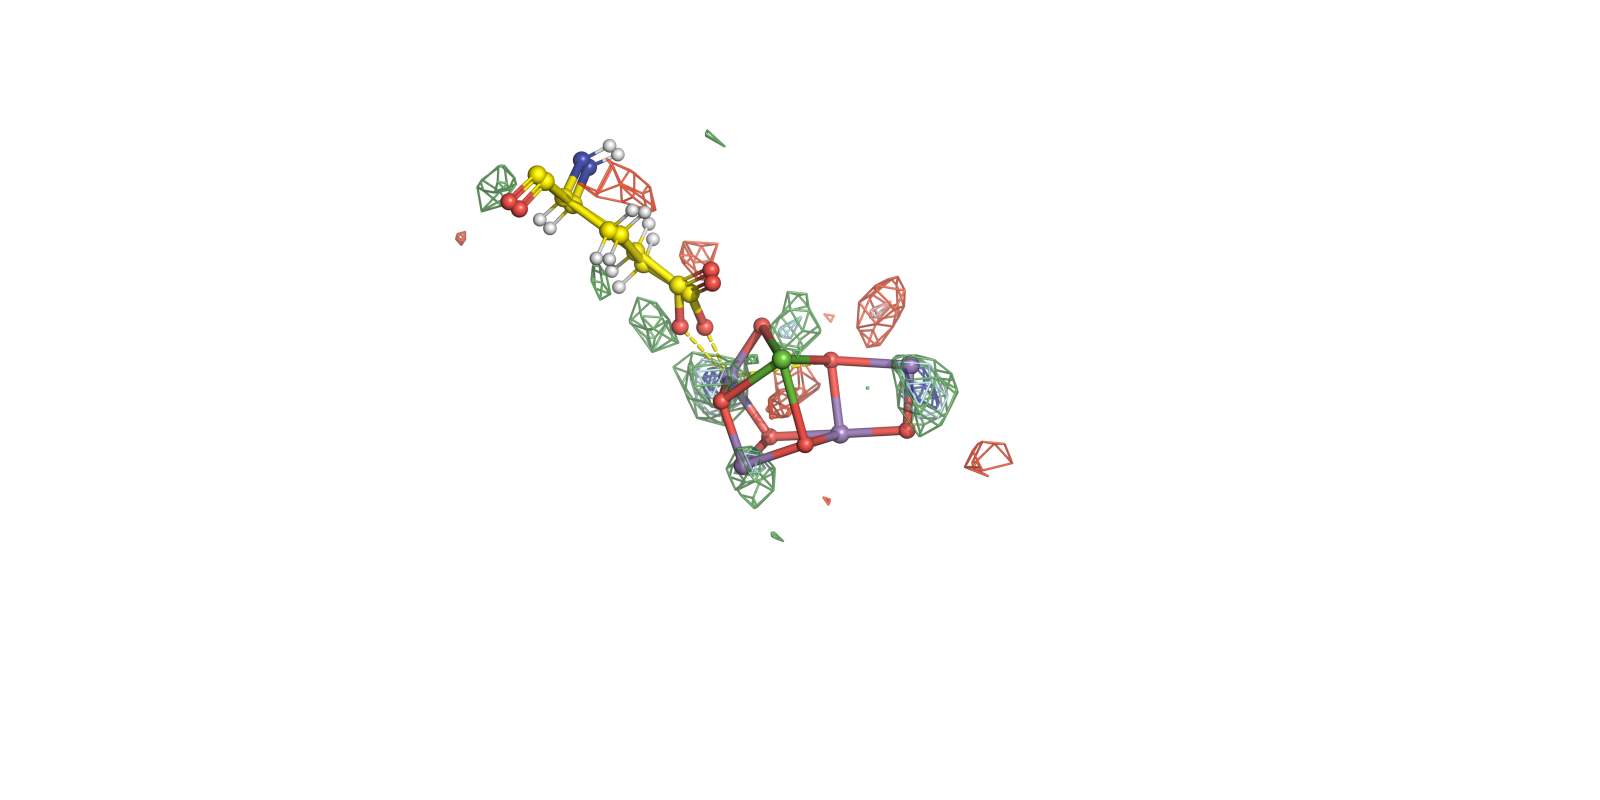

Launching PyMOL. Adjust the view, then quit the window.
 PyMOL(TM) Molecular Graphics System, Version 3.1.0.
 Copyright (c) Schrodinger, LLC.
 All Rights Reserved.
 
    Created by Warren L. DeLano, Ph.D. 
 
    PyMOL is user-supported open-source software.  Although some versions
    are freely available, PyMOL is not in the public domain.
 
    If PyMOL is helpful in your work or study, then please volunteer 
    support for our ongoing efforts to create open and affordable scientific
    software by purchasing a PyMOL Maintenance and/or Support subscription.

    More information can be found at "http://www.pymol.org".
 
    Enter "help" for a list of commands.
    Enter "help <command-name>" for information on a specific command.

 Hit ESC anytime to toggle between text and graphics.

 Detected OpenGL version 2.1. Shaders available.
 Tessellation shaders not available
 Detected GLSL version 1.20.
 OpenGL graphics engine:
  GL_VENDOR:   Apple
  GL_RENDERER: Apple M1
  GL_VERSION:  2

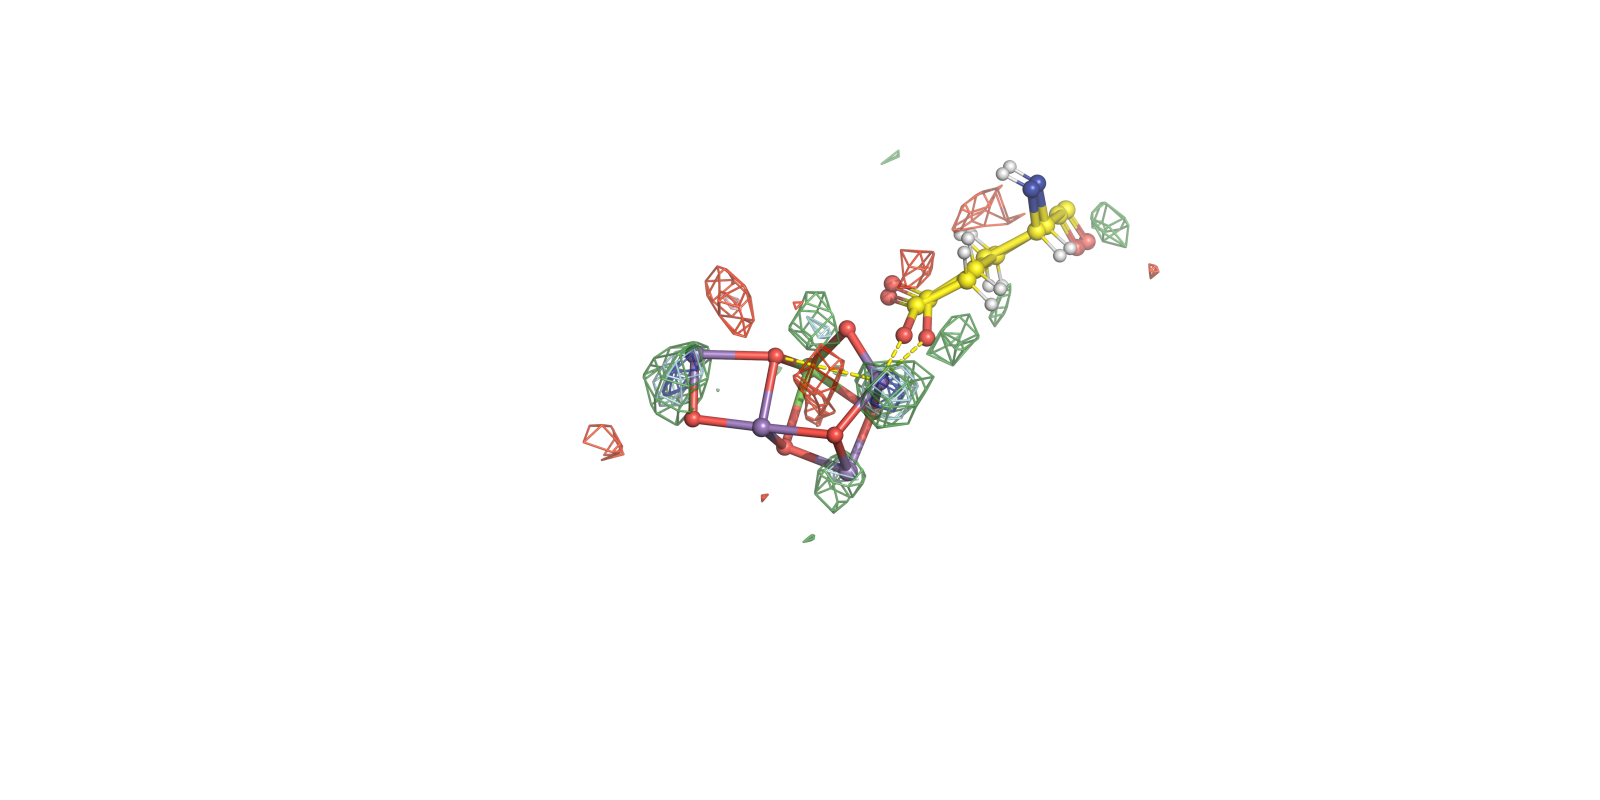

In [ ]:
pos_levels = list(SIGMA_POSITIVE if SIGMA_POSITIVE is not None else SIGMA_LEVELS)
neg_levels = list(SIGMA_NEGATIVE if SIGMA_NEGATIVE is not None else SIGMA_LEVELS)
pos_levels = sorted(float(x) for x in pos_levels)
neg_levels = sorted(float(x) for x in neg_levels)

site_sel = f"xyz and chain {SITE_CHAIN} and resi {SITE_RESI}"
png_path = OUTPUT_DIR / f"{LIGHT_ID}_minus_{DARK_ID}_{SITE_LABEL}_{SITE_CHAIN}{SITE_RESI}_diffmap.png"
pml_path = OUTPUT_DIR / f"pymol_{LIGHT_ID}_minus_{DARK_ID}_{SITE_LABEL}.pml"

oec_pairs = [
    ("MN1", "O1"), ("MN1", "O3"), ("MN1", "O6"),
    ("MN2", "O1"), ("MN2", "O2"), ("MN2", "O3"),
    ("MN3", "O2"), ("MN3", "O3"), ("MN3", "O4"), ("MN3", "O5"),
    ("MN4", "O5"), ("MN4", "O4"),
    ("CA1", "O1"), ("CA1", "O2"), ("CA1", "O5"), ("CA1", "O6"),
]

stats = ccp4_map_stats(fragment)
print(
    f"Fragment file stats (raw voxels): RMS={stats['rms']:.5f}  "
    f"mean={stats['mean']:.5f}  min={stats['min']:.5f}  max={stats['max']:.5f}  "
    f"grid={int(stats['nx'])}x{int(stats['ny'])}x{int(stats['nz'])}"
)
if CONTOUR_MODE == "sigma":
    # PyMOL normalizes CCP4 maps to mean 0 / RMS 1, so isomesh level n is n-sigma.
    pos_abs = list(pos_levels)
    neg_abs = [-n for n in neg_levels]
    normalize_flag = 1
    print("Contour mode: PyMOL-normalized sigma (isomesh level n = n sigma)")
else:
    pos_abs = list(pos_levels)
    neg_abs = [-n for n in neg_levels]
    normalize_flag = 0
    print("Contour mode: absolute map units (normalize_ccp4_maps off)")

if surface_representation == "mesh":
    contour_cmd = "isomesh"
    surface_transparency = 0.25
elif surface_representation == "solid":
    contour_cmd = "isosurface"
    surface_transparency = 0.45
else:
    raise ValueError(
        "surface_representation must be 'mesh' or 'solid', "
        f"got {surface_representation!r}"
    )
print(f"Surface representation: {surface_representation} ({contour_cmd})")

lines: list[str] = [
    f"set normalize_ccp4_maps, {normalize_flag}",
    f"load {fragment}, DIFF",
    f"load {FILES['light_pdb']}, xyz",
    "hide everything",
    "util.cbay xyz",
    f"select site, {site_sel}",
    "show spheres, site",
    "show sticks, site",
    "set sphere_scale, 0.15, xyz",
    "set stick_radius, 0.12, xyz",
]

for extra in EXTRA_RESIDUES:
    lab = extra.get("label", f"{extra['chain']}{extra['resi']}")
    lines += [
        f"select {lab}, xyz and chain {extra['chain']} and resi {extra['resi']}",
        f"show sticks, {lab}",
        f"show spheres, {lab}",
        f"set sphere_scale, 0.15, {lab}",
        f"set stick_radius, 0.12, {lab}",
    ]

if SHOW_OEC_BONDS:
    present = residue_atom_names(FILES["light_pdb"], SITE_CHAIN, SITE_RESI)
    for a, b in oec_pairs:
        if a in present and b in present:
            lines.append(f"bond site and name {a}, site and name {b}")

if DRAW_DEFAULT_OEC_DISTANCES:
    present = residue_atom_names(FILES["light_pdb"], SITE_CHAIN, SITE_RESI)
    if "MN1" in present and "O5" in present:
        lines.append("distance d_mn1_o5, site and name MN1, site and name O5")
    for extra in EXTRA_RESIDUES:
        extra_atoms = residue_atom_names(FILES["light_pdb"], extra["chain"], extra["resi"])
        if "MN1" in present and "OE2" in extra_atoms:
            lab = extra.get("label", f"{extra['chain']}{extra['resi']}")
            lines.append(
                f"distance d_mn1_{lab}_A, site and name MN1, {lab} and alt A and name OE2"
            )
            lines.append(
                f"distance d_mn1_{lab}_B, site and name MN1, {lab} and alt B and name OE2"
            )

lines += [
    "viewport %d,%d" % (PNG_WIDTH, PNG_HEIGHT),
    "bg_color white",
    "space cmyk",
    "set ray_opaque_background, 1",
    "set ray_trace_mode, 0",
    "set ray_trace_fog, 1",
    "set orthoscopic, on",
    "set antialias, 4",
    "set mesh_width, 0.25",
    "set dash_gap, 0.15",
    "set dash_radius, 0.05",
    "hide labels",
    "set auto_zoom, 0",
]

carve_target = "site"
for extra in EXTRA_RESIDUES:
    carve_target += " or " + extra.get("label", f"{extra['chain']}{extra['resi']}")
lines.append(f"select carve_sel, {carve_target}")

for i, (n, level) in enumerate(zip(pos_levels, pos_abs)):
    name = "mappos_" + str(n).replace(".", "p")
    color = POS_COLORS[min(i, len(POS_COLORS) - 1)]
    lines += [
        f"{contour_cmd} {name}, DIFF, {level:.6f}, carve_sel, carve={CARVE_A:.2f}",
        f"color {color}, {name}",
    ]
    print(f"  +{n:g} sigma -> {name} at {level:.5f} ({color})")
for i, (n, level) in enumerate(zip(neg_levels, neg_abs)):
    name = "mapneg_" + str(n).replace(".", "p")
    color = NEG_COLORS[min(i, len(NEG_COLORS) - 1)]
    lines += [
        f"{contour_cmd} {name}, DIFF, {level:.6f}, carve_sel, carve={CARVE_A:.2f}",
        f"color {color}, {name}",
    ]
    print(f"  -{n:g} sigma -> {name} at {level:.5f} ({color})")
if surface_representation == "mesh":
    lines.append("set mesh_width, 0.75, map*")
lines.append(f"set transparency, {surface_transparency:.2f}, map*")

def pymol_camera_commands(view_numbers):
    if not view_numbers:
        return ["orient site", "zoom site, 8"]
    if len(view_numbers) != 18:
        raise ValueError(f"PyMOL view must contain 18 numbers, got {len(view_numbers)}")
    return [
        "python",
        "from pymol import cmd",
        f"cmd.set_view({tuple(float(x) for x in view_numbers)!r})",
        "python end",
    ]


def parse_pymol_view(text):
    if text is None or not str(text).strip():
        return None
    nums = [float(x) for x in re.findall(r"[-+]?(?:\d+\.?\d*|\.\d+)", str(text))]
    if len(nums) != 18:
        raise ValueError(f"PYMOL_VIEW must contain 18 numbers, got {len(nums)}")
    return nums


def format_pymol_view(nums):
    rows = [nums[i:i + 3] for i in range(0, 18, 3)]
    return ",\\\n".join(", ".join(f"{x: .9f}" for x in row) for row in rows)


def run_pymol_headless(script_lines):
    pml_path.write_text("\n".join(script_lines) + "\n")
    print("Wrote", pml_path)
    print("Running PyMOL headless…")
    proc = subprocess.run(
        [str(PYMOL_BIN), "-cq", str(pml_path)],
        cwd=str(OUTPUT_DIR),
        text=True,
        capture_output=True,
    )
    log_path = OUTPUT_DIR / "pymol_render.log"
    log_path.write_text((proc.stdout or "") + (proc.stderr or ""))
    print(proc.stdout or "")
    if proc.returncode == 0 and png_path.is_file():
        return
    # Retry without ray tracing — some macOS builds need a display for ray.
    if RAY_TRACE and any(ln.startswith("png ") and "ray=1" in ln for ln in script_lines):
        print("Ray-traced PNG failed; retrying with ray=0 …")
        fallback = [
            ln.replace("ray=1", "ray=0") if ln.startswith("png ") else ln
            for ln in script_lines
        ]
        pml_path.write_text("\n".join(fallback) + "\n")
        proc = subprocess.run(
            [str(PYMOL_BIN), "-cq", str(pml_path)],
            cwd=str(OUTPUT_DIR),
            text=True,
            capture_output=True,
        )
        log_path.write_text((proc.stdout or "") + (proc.stderr or ""))
        print(proc.stdout or "")
    if proc.returncode != 0 or not png_path.is_file():
        raise RuntimeError(f"PyMOL failed (exit {proc.returncode}). See {log_path}")


def publish_png():
    print("Saved image:", png_path)
    visible = NOTEBOOK_DIR / png_path.name
    if visible.resolve() != png_path.resolve():
        shutil.copy2(png_path, visible)
        print("Copied image:", visible)


scene_lines = list(lines)
ray_flag = 1 if RAY_TRACE else 0
png_cmd = f"png {png_path}, {PNG_WIDTH}, {PNG_HEIGHT}, dpi=200, ray={ray_flag}"
camera = pymol_camera_commands(parse_pymol_view(PYMOL_VIEW))
run_pymol_headless(scene_lines + camera + [png_cmd, "quit"])
publish_png()
sigma_txt = ", ".join(f"+/-{s:g}" for s in pos_levels)
display(Markdown(
    f"**{LIGHT_ID} - {DARK_ID}** difference density around "
    f"`{SITE_LABEL}` {SITE_CHAIN}/{SITE_RESI}, "
    f"contoured at {sigma_txt} sigma "
    f"(positive = stronger in {LIGHT_ID}; negative = stronger in {DARK_ID})."
))
display(Image(filename=str(png_path), width=min(PNG_WIDTH, 1100)))

# INSPECT_IN_PYMOL (configuration cell): open this scene in the PyMOL GUI,
# change the camera, then quit. A moved view is saved and the PNG is redrawn.
if INSPECT_IN_PYMOL:
    view_file = OUTPUT_DIR / "pymol_view.txt"
    view_file.unlink(missing_ok=True)
    inspect_pml = pml_path.with_name(pml_path.stem + "_inspect.pml")
    hook = [
        "python",
        "from pymol import cmd",
        "import threading",
        "import time",
        f"_VIEW_FILE = {str(view_file)!r}",
        "def write_view(echo=1):",
        "    view = cmd.get_view(quiet=1)",
        "    fh = open(_VIEW_FILE, 'w')",
        "    fh.write('\\n'.join('%.9f' % float(x) for x in view))",
        "    fh.close()",
        "    if int(echo):",
        "        print('Wrote PyMOL view to %s' % _VIEW_FILE)",
        "def _watch_view():",
        "    initial = None",
        "    while True:",
        "        try:",
        "            view = [float(x) for x in cmd.get_view(quiet=1)]",
        "            if initial is None:",
        "                initial = view",
        "            elif max(abs(a - b) for a, b in zip(view, initial)) >= 1e-4:",
        "                write_view(0)",
        "        except Exception:",
        "            return",
        "        time.sleep(0.5)",
        "cmd.extend('write_view', write_view)",
        "threading.Thread(target=_watch_view, daemon=True).start()",
        "print('Adjust the view, then quit PyMOL.')",
        "print('If the notebook does not pick up the camera, run write_view before quitting.')",
        "python end",
    ]
    inspect_pml.write_text("\n".join(scene_lines + camera + hook) + "\n")
    print("Launching PyMOL. Adjust the view, then quit the window.")
    proc = subprocess.run(
        [str(PYMOL_BIN), str(inspect_pml)],
        cwd=str(OUTPUT_DIR),
    )
    if proc.returncode not in (0, None):
        print(f"PyMOL exited with status {proc.returncode}.")
    if not view_file.is_file():
        print("View unchanged.")
    else:
        saved = [float(x) for x in view_file.read_text().split()]
        if len(saved) != 18:
            raise RuntimeError(f"Unexpected PyMOL view in {view_file}")
        PYMOL_VIEW = format_pymol_view(saved)
        print("Camera updated for this session. Paste this into the configuration cell to keep it:")
        print("PYMOL_VIEW = '''\\")
        print(PYMOL_VIEW)
        print("'''")
        camera = pymol_camera_commands(saved)
        png_path.unlink(missing_ok=True)
        run_pymol_headless(scene_lines + camera + [png_cmd, "quit"])
        publish_png()
        display(Image(filename=str(png_path), width=min(PNG_WIDTH, 1100)))


## Interpreting the default PSII figure

For `6w1v` (2F) minus `6w1o` (0F) around OEY A416 you should see:

- The Mn$_4$CaO$_5$ cubane plus the dangling Mn4, with O6 present in the major LIGHT conformation.
- Difference peaks on the cluster and on D1-Glu189, which is modelled with two alternate conformations in the 2F structure.
- **No requirement** that a strong positive peak sit exactly on O6. Whether 2F XFEL data support an inserted oxo/water at that position is debated in the literature; this notebook reproduces the *map*, it does not settle that debate.

If the mesh is empty, raise the noise or lower `SIGMA_LEVELS` (try `[3.0]`). If the cage swallows the model, decrease `CARVE_A` or raise the $\sigma$ cutoff. The original `.pml` used `CONTOUR_MODE = "sigma"` with `[3, 4, 5]` and PyMOL's built-in map normalisation.

## Adapting the notebook

1. Put the six files for your two PDB entries in `INPUT_DIR` (or point the six path variables at them).
2. Set `DARK_ID` / `LIGHT_ID` and `PHASE_SOURCE`. Leave `RESOLUTION_SOURCE = "sf"` to take the common shell of the two structure-factor MTZs, or set `RESOLUTION_SOURCE = "explicit"` and fill in `LOWRES` / `DMIN`.
3. Run through the residue-scan cell, then set `SITE_CHAIN` / `SITE_RESI` / `EXTRA_RESIDUES`.
4. Set `PYMOL_VIEW = None` unless you have a camera you want to reuse.
5. Set `RECOMPUTE_MAP = True` the first time; afterwards leave it `False` while you tune $\sigma$ and the view.

To change the camera, set `INSPECT_IN_PYMOL = True` and re-run the render cell. Quit PyMOL when the view looks right; paste the printed matrix into `PYMOL_VIEW` to keep it. You can also open the extended map in Coot with `coot {extended_map} {light_pdb}`.
